In [1]:
from sherpa.astro import ui
from astropy.io import fits
from astropy.table import Table

In [2]:
from sherpa.astro.io import read_pha, read_arf, read_rmf

In [111]:
TG_PART = {1: 'HEG', 2: 'MEG', 3: 'LEG'}

tgcat_id = 2459
tgcat_id = 6972

phalist = read_pha(f"/Users/guenther/data/tg_test_data/arcA/pha2/tgcid_{tgcat_id}_pha2.gz")
phas = {}
for pha in phalist:
    tg_m = int(pha.header['TG_M'])
    tg_part = int(pha.header['TG_PART'])
    if abs(tg_m) > 1:
        continue
    arf = read_arf(f"/Users/guenther/data/tg_test_data/arcA/arf/tgcid_{tgcat_id}_{TG_PART[tg_part]}_{tg_m}.arf.gz")
    #rmf = read_rmf(
    #    f"/Users/guenther/data/tg_test_data/arcA/rmf/tgcid_{tgcat_id}_{TG_PART[tg_part]}_{tg_m}.rmf.gz"
    #)
    pha.set_response(arf, None)
    phas[TG_PART[tg_part], int(tg_m)] = pha

statistical errors were found in file '/Users/guenther/data/tg_test_data/arcA/pha2/tgcid_6972_pha2.gz'
but not used; to use them, re-read with use_errors=True
read background_up into a dataset from file /Users/guenther/data/tg_test_data/arcA/pha2/tgcid_6972_pha2.gz
read background_down into a dataset from file /Users/guenther/data/tg_test_data/arcA/pha2/tgcid_6972_pha2.gz


In [4]:
from sherpa.astro.plot import DataPHAPlot
from sherpa.stats import Chi2, Chi2Gehrels, Cash, CStat, LeastSq, Likelihood, Poisson, WStat

ImportError: cannot import name 'Poisson' from 'sherpa.stats' (/Users/guenther/miniforge3/envs/ciao-4.18/lib/python3.12/site-packages/sherpa/stats/__init__.py)

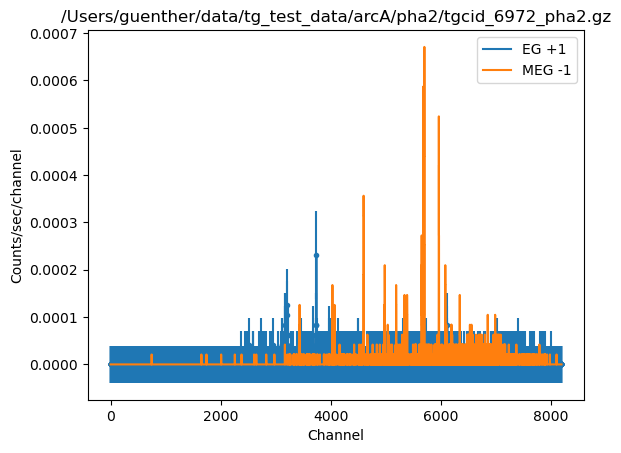

In [5]:
dataplot = DataPHAPlot()
dataplot.prepare(phas[('HEG', 1)], stat=Chi2Gehrels())
dataplot.plot(label="EG +1", linestyle='-', yerrorbars=True)
dataplot.prepare(phas[("MEG", -1)])
dataplot.plot(overplot=True, label="MEG -1", linestyle='-', marker=None)

In [7]:
hm1 = phas[("HEG", -1)]
hp1 = phas[("HEG", 1)]
mm1 = phas[("MEG", -1)]
mp1 = phas[("MEG", 1)]

In [28]:
hm1.exposure, hp1.exposure

(np.float64(47696.490944906), np.float64(47696.490944906))

In [8]:
am1 = hm1.get_arf(1)
ap1 = hp1.get_arf(1)


In [23]:
import numpy as np
arr = np.arange(10)
arr.reshape(-1, 2).sum(axis=1)

array([ 1,  5,  9, 13, 17])

In [ ]:
import copy
from sherpa.astro.data import DataPHA

# We don't need a general solution, only the following scenarios
# LEG-1 / LEG + 1
# HEG-1 / HEG + 1
# MEG-1 / MEG + 1
# HEG-1 / HEG + 1 / MEG-1 / MEG + 1
# In all except the last scenario, the energy grid all the inputs matches.

def coadd(phas: list[DataPHA]) -> DataPHA:
    """Coadd multiple DataPHA objects into a single DataPHA object.

    Parameters
    ----------
    phas : list[DataPHA]
        List of DataPHA objects to coadd.

    Returns
    -------
    DataPHA
        Coadded DataPHA object.
    """
    if not phas:
        raise ValueError("No DataPHA objects provided for coaddition.")

    tg_parts = [pha.header.get("TG_PART") for pha in phas]
    if not set(tg_parts) in [{1}, {2}, {3}, {1, 2}]:
        raise ValueError(f"Unsupported combination of TG_PART values: {tg_parts}")

    # Ensure all DataPHA objects have the same exposure time
    exposure = phas[0].exposure
    if not all(pha.exposure == exposure for pha in phas):
        raise ValueError("All DataPHA objects must have the same exposure time.")

    # Create a new DataPHA object for the coadded result
    if set(tg_parts) == {1, 2}:
        # HEG/MEG
        # We will use the wider energy grid from the MEG (TG_PART=2).
        # and bin the HEG data to match the MEG energy grid.
        base_index = tg_parts.index(2)
    else:
        base_index = 0
    
    coadded_pha = copy.deepcopy(phas[base_index])
    combined_arf = copy.deepcopy(phas[base_index].get_arf(1))
    
    # Sum counts and combine ARFs
    coadded_pha.counts[:] = 0
    combined_arf.dep[:] = 0

    for pha in phas:
        # Check some of the simplifying assumptions
        assert pha._response_ids == phas[base_index]._response_ids

        # This could be unified, but for readability,
        # we write out "bin HEG on MEG grid" separately.
        # We also assume that HEG and MEG have standard CIAO binning,
        # i.e. same number of bins and MEG is exactly twice the HEG bins.
        if pha.header.get("TG_PART") == 1 and set(tg_parts) == {1, 2}:
            binned_counts = pha.counts.reshape(-1, 2).sum(axis=1)
            coadded_pha.counts[len(binned_counts):] += binned_counts

            binned_arf = pha.get_arf(1).dep.reshape(-1, 2).mean(axis=1)
            combined_arf.dep[len(binned_arf):] += binned_arf
        else:
            coadded_pha.counts += pha.counts
            # All PHA are HRC or ACIS, so they all have either
            # just one or multiple ARFs.
            # Otherwise, assigning to an ARF that doesn't exist would be problematic.
            for i in pha._response_ids:
                combined_arf.dep += pha.get_arf(i).dep
    

    coadded_pha.set_response(combined_arf, None)

    return coadded_pha 

In [96]:
phas = [hm1, hp1, mm1, mp1]
tg_parts = [pha.header.get("TG_PART") for pha in phas]
base_index = tg_parts.index(2)

coadded_pha = copy.deepcopy(phas[base_index])
combined_arf = copy.deepcopy(phas[base_index].get_arf(1))

# Sum counts and combine ARFs
coadded_pha.counts[:] = 0
combined_arf.dep[:] = 0

In [107]:
    for pha in phas:
        # Check some of the simplifying assumptions
        assert pha._response_ids == phas[base_index]._response_ids

        # This could be unified, but for readability,
        # we write out "bin HEG on MEG grid" separately.
        # We also assume that HEG and MEG have standard CIAO binning,
        # i.e. same number of bins and MEG is exactly twice the HEG bins.
        if pha.header.get("TG_PART") == 1 and set(tg_parts) == {1, 2}:
            binned_counts = pha.counts.reshape(-1, 2).sum(axis=1)
            coadded_pha.counts[len(binned_counts):] += binned_counts

            binned_arf = pha.get_arf(1).dep.reshape(-1, 2).mean(axis=1)
            combined_arf.dep[len(binned_arf):] += binned_arf
        else:
            coadded_pha.counts += pha.counts
            # All PHA are HRC or ACIS, so they all have either
            # just one or multiple ARFs.
            # Otherwise, assigning to an ARF that doesn't exist would be problematic.
            for i in pha._response_ids:
                combined_arf.dep += pha.get_arf(i).dep
        print(pha.counts.sum(), coadded_pha.counts.sum())

666.0 4057.0
526.0 4583.0
2059.0 6642.0
1606.0 8248.0


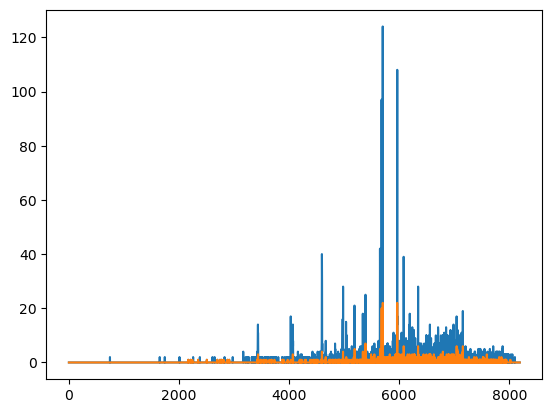

In [108]:
plt.plot(coadded_pha.counts)
plt.plot(pha.counts)

In [91]:
binned_counts.sum()


np.float64(526.0)

In [85]:
arf_hm1 = hm1.get_arf(1)
arf_mm1 = mm1.get_arf(1)

In [86]:
coadded_pha = coadd([hm1,hp1, mm1, mp1])
coadded_pha.ungroup()
coadded_pha.set_analysis("wave")

[np.int16(1), np.int16(1), np.int16(2), np.int16(2)] 2


Text(0, 0.5, 'Counts/sec/Angstrom')

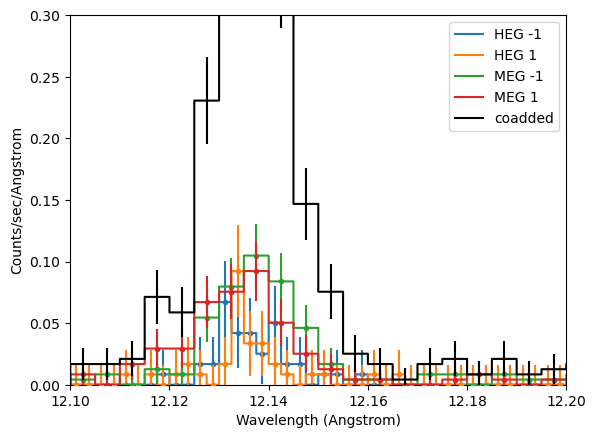

In [112]:
dataplot = DataPHAPlot()

for k, v in phas.items():
    v.ungroup()
    v.set_analysis("wave")
    dataplot.prepare(v, stat=Chi2Gehrels())
    dataplot.plot(label=f"{k[0]} {k[1]}", linestyle="-", yerrorbars=True, overplot=True)

dataplot.prepare(coadded_pha, stat=Chi2Gehrels())
dataplot.plot(overplot=True, label="coadded", linestyle="-", marker=None, color="k")

import matplotlib.pyplot as plt

ax = plt.gca()
ax.set_xlim(12.1, 12.2)
ax.set_ylim(0, 0.3)
ax.set_xlabel(dataplot.xlabel)
ax.set_ylabel(dataplot.ylabel)


HEG -1: 47.0
HEG 1: 41.0
MEG -1: 140.0
MEG 1: 141.0
coadded: 603.0


(1.01, 1.05)

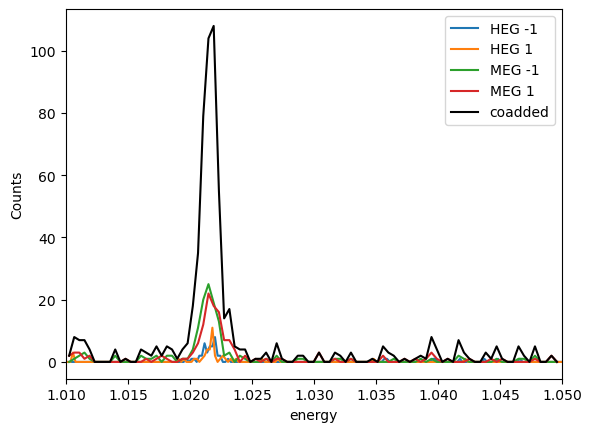

In [113]:
fig, ax = plt.subplots()

for k, v in phas.items():
    v.ungroup()
    v.set_analysis("wave")
    en = v.get_arf(1).x
    ind = (en >= 1.01) & (en <= 1.05)
    ax.plot(v.get_arf(1).x[ind], v.counts[ind], label=f"{k[0]} {k[1]}")
    print(f"{k[0]} {k[1]}: {v.counts[ind].sum()}")

en = coadded_pha.get_arf(1).x
ind = (en >= 1.01) & (en <= 1.05)
ax.plot(coadded_pha.get_arf(1).x[ind], coadded_pha.counts[ind], label="coadded", linestyle="-", marker=None, color="k")
print(f"coadded: {coadded_pha.counts[ind].sum()}")
ax.set_xlabel("energy")
ax.set_ylabel("Counts")
ax.legend()
ax.set_xlim(1.01, 1.05)

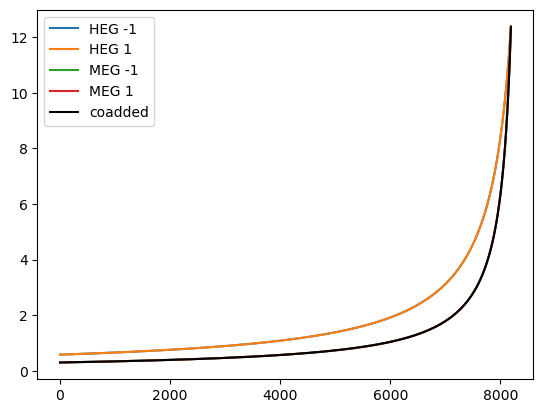

In [59]:
fig, ax = plt.subplots()

for k, v in phas.items():
    v.ungroup()
    v.set_analysis("energy")
    ax.plot(v.get_arf(1).x, label=f"{k[0]} {k[1]}")

ax.plot(
    coadded_pha.get_arf(1).x,
    label="coadded",
    linestyle="-",
    marker=None,
    color="k",
)

ax.legend()


In [46]:
arf.x

array([ 0.29549946,  0.29553467,  0.2955699 ,  0.29560514,  0.29564039,
        0.29567565,  0.29571091,  0.29574616,  0.29578143,  0.29581672,
        0.29585202,  0.29588732,  0.29592262,  0.29595795,  0.29599328,
        0.29602861,  0.29606396,  0.29609932,  0.29613468,  0.29617004,
        0.29620542,  0.29624081,  0.29627621,  0.29631162,  0.29634702,
        0.29638244,  0.29641788,  0.29645331,  0.29648876,  0.29652421,
        0.29655966,  0.29659514,  0.29663064,  0.29666612,  0.29670161,
        0.29673712,  0.29677263,  0.29680815,  0.29684368,  0.29687922,
        0.29691477,  0.29695033,  0.29698589,  0.29702148,  0.29705706,
        0.29709265,  0.29712825,  0.29716386,  0.29719947,  0.29723509,
        0.29727072,  0.29730636,  0.29734202,  0.29737768,  0.29741333,
        0.29744901,  0.2974847 ,  0.2975204 ,  0.2975561 ,  0.29759181,
        0.29762752,  0.29766326,  0.29769899,  0.29773474,  0.29777049,
        0.29780625,  0.29784203,  0.2978778 ,  0.2979136 ,  0.29

In [75]:
arr = np.ones(10)
arr2 = np.arange(5)
arr[5:] += arr2

arr

array([1., 1., 1., 1., 1., 1., 2., 3., 4., 5.])

In [ ]:
def coadd(phas: list[DataPHA]) -> DataPHA:
    """Coadd multiple DataPHA objects into a single DataPHA object.

    Parameters
    ----------
    phas : list[DataPHA]
        List of DataPHA objects to coadd.

    Returns
    -------
    DataPHA
        Coadded DataPHA object.

    Notes
    -----
    This function assumes that the input DataPHA objects have standard CIAO binning.

    We don't need a general solution, only the following scenarios
    LEG-1 / LEG + 1
    HEG-1 / HEG + 1
    MEG-1 / MEG + 1
    HEG-1 / HEG + 1 / MEG-1 / MEG + 1
    In all except the last scenario, the energy grid all the inputs matches.

    """
    if not phas:
        raise ValueError("No DataPHA objects provided for coaddition.")

    tg_parts = [pha.header.get("TG_PART") for pha in phas]
    if not set(tg_parts) in [{1}, {2}, {3}, {1, 2}]:
        raise ValueError(f"Unsupported combination of TG_PART values: {tg_parts}")

    # Ensure all DataPHA objects have the same exposure time
    exposure = phas[0].exposure
    if not all(pha.exposure == exposure for pha in phas):
        raise ValueError("All DataPHA objects must have the same exposure time.")

    # Create a new DataPHA object for the coadded result
    if set(tg_parts) == {1, 2}:
        # HEG/MEG
        # We will use the wider energy grid from the MEG (TG_PART=2).
        # and bin the HEG data to match the MEG energy grid.
        base_index = tg_parts.index(2)
    else:
        base_index = 0

    coadded_pha = copy.deepcopy(phas[base_index])
    combined_arf = copy.deepcopy(phas[base_index].get_arf(1))

    # Check some of the simplifying assumptions
    assert coadded_pha.counts is not None, "We assume all spectra contain data"
    assert combined_arf is not None, "We assume the ARF is set"
    assert combined_arf.dep is not None, "We assume the ARF has a valid data"

    # Sum counts and combine ARFs
    coadded_pha.counts[:] = 0
    combined_arf.dep[:] = 0

    for pha in phas:
        # Check some of the simplifying assumptions
        assert pha._response_ids == phas[base_index]._response_ids
        assert pha.counts is not None, "We assume all spectra contain data"

        # This could be unified, but for readability,
        # we write out "bin HEG on MEG grid" separately.
        # We also assume that HEG and MEG have standard CIAO binning,
        # i.e. same number of bins and MEG is exactly twice the HEG bins.
        if pha.header.get("TG_PART") == 1 and set(tg_parts) == {1, 2}:
            binned_counts = pha.counts.reshape(-1, 2).sum(axis=1)
            coadded_pha.counts[len(binned_counts) :] += binned_counts

            for i in pha._response_ids:
                binned_arf = pha.get_arf(i).dep.reshape(-1, 2).mean(axis=1)
                combined_arf.dep[len(binned_arf) :] += binned_arf
        else:
            coadded_pha.counts += pha.counts
            # All PHA are HRC or ACIS, so they all have either
            # just one or multiple ARFs.
            # Otherwise, assigning to an ARF that doesn't exist would be problematic.
            for i in pha._response_ids:
                combined_arf.dep += pha.get_arf(i).dep

    coadded_pha.set_response(combined_arf, None)

    return coadded_pha
